In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

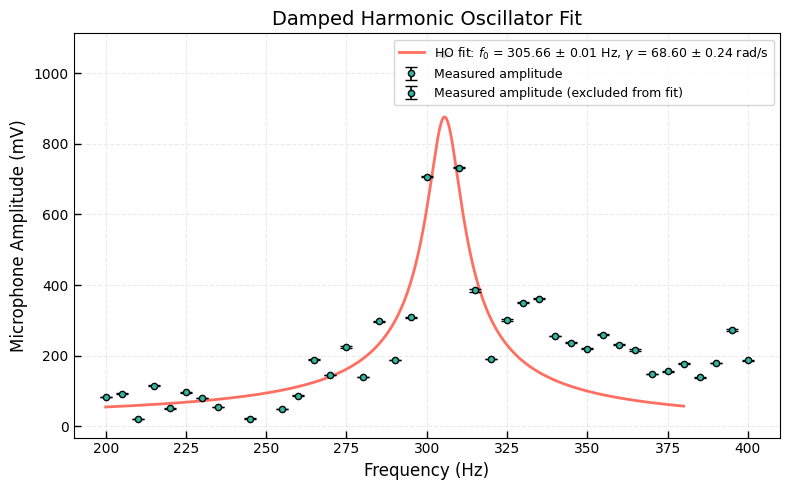

C     = 1.154e+08 ± 1.02e+05
f0    = 305.6568 ± 0.0132 Hz
gamma = 68.5951 ± 0.2364 rad/s


In [3]:
df = pd.read_csv("resonance_phase_data_90mV_200-450Hz.csv")
freq = df['Frequency_Hz'].values
mic_amp = df['Mic_Amplitude_mV'].values
mic_err = df['Mic_Amplitude_Err_mV'].values
freq_fit_range = (freq >= 200) & (freq <= 380)
mic_amp_fit = mic_amp[freq_fit_range]
mic_err_fit = mic_err[freq_fit_range]


# Single damped harmonic oscillator
def amplitude_model(f_hz, C, f0_hz, gamma):
    omega = 2 * np.pi * f_hz
    omega0 = 2 * np.pi * f0_hz

    return C / np.sqrt(
        (omega0**2 - omega**2)**2 + (gamma * omega)**2
    )

# Initial guesses: scale, resonance frequency, damping
p0 = [1e8, freq[np.argmax(mic_amp)], 100.0]

# Weighted nonlinear least-squares fit
popt, pcov = curve_fit(
    amplitude_model,
    freq[freq_fit_range],
    mic_amp_fit,
    p0=p0,
    sigma=mic_err_fit,
    absolute_sigma=True,
    bounds=([0, 0, 0], [np.inf, np.inf, np.inf]),
    maxfev=50000
)

C_fit, f0_fit, gamma_fit = popt
perr = np.sqrt(np.diag(pcov))
C_err, f0_err, gamma_err = perr

# Smooth frequency range for the fitted curve
f_smooth = np.linspace(freq.min(), freq.max()-20, 1000)
amp_fit = amplitude_model(f_smooth, *popt)

# Plot data and fit
plt.figure(figsize=(8, 5))

plt.errorbar(
    freq[freq_fit_range], mic_amp_fit,
    yerr=mic_err_fit,
    fmt='o',
    color='#007C91',
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    markersize=4.5,
    markerfacecolor="#2FB9A4",
    markeredgecolor="#010607",
    linestyle='none',
    label='Measured amplitude',
    zorder=3
)

plt.plot(
    f_smooth, amp_fit,
    color='#FF6F61',
    linewidth=2,
    label=(
        f'HO fit: $f_0$ = {f0_fit:.2f} ± {f0_err:.2f} Hz, '
        f'$\\gamma$ = {gamma_fit:.2f} ± {gamma_err:.2f} rad/s'
    )
)
# plot 4 points after 380
plt.errorbar(
    freq[~freq_fit_range], mic_amp[~freq_fit_range],
    yerr=mic_err[~freq_fit_range],
    fmt='o',
    color='#007C91',
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    markersize=4.5,
    markerfacecolor="#2FB9A4",
    markeredgecolor="#010607",
    linestyle='none',
    label='Measured amplitude (excluded from fit)',
    zorder=3
)
plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel('Microphone Amplitude (mV)', fontsize=12)
plt.title('Damped Harmonic Oscillator Fit', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.25)
plt.legend(fontsize=9)
plt.tick_params(direction='in', length=5, width=1)
plt.tight_layout()
plt.show()

# Print fitted parameters
print(f"C     = {C_fit:.6g} ± {C_err:.3g}")
print(f"f0    = {f0_fit:.4f} ± {f0_err:.4f} Hz")
print(f"gamma = {gamma_fit:.4f} ± {gamma_err:.4f} rad/s")



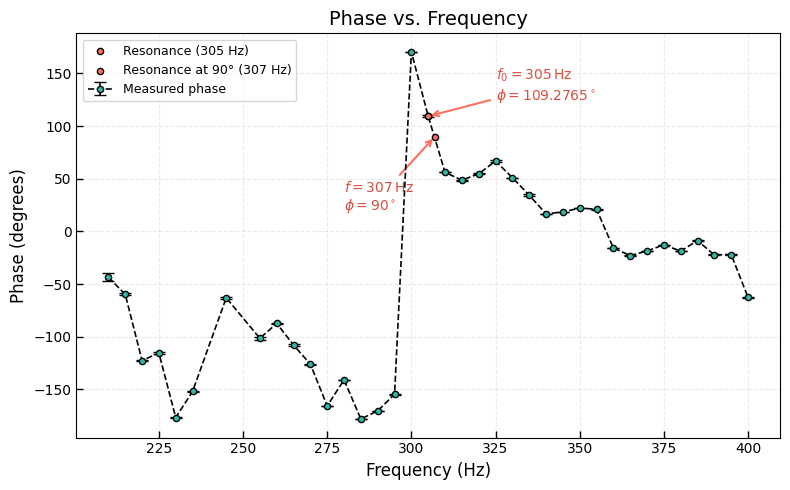

In [4]:
df = pd.read_csv("resonance_phase_data_90mV_200-450Hz.csv")
freq = df['Frequency_Hz'].values
phase = df['Phase_Difference_deg'].values
phase_err = df['Phase_Difference_Err_deg'].values
freq_fit_range = (freq >= 210) & (freq <= 400)
phase_fit = phase[freq_fit_range]
phase_err_fit = phase_err[freq_fit_range]

# f_smooth = np.linspace(freq.min(), freq.max(), 1000)
# # phase model
# def phase_model(f_hz):
#     omega = 2 * np.pi * f_hz
#     omega0 = 2 * np.pi * 305

#     return np.rad2deg(np.arctan2(68.59 * omega, omega0**2 - omega**2))
# # just model plot
# y = phase_model(f_smooth) 
# plot with error bars
plt.figure(figsize=(8, 5))
plt.errorbar(
    freq[freq_fit_range], phase_fit,
    yerr=phase_err_fit,
    fmt='o',
    color="#010405",
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    markersize=4.5,
    markerfacecolor="#2FB9A4",
    markeredgecolor="#010607",
    linestyle='--',
    linewidth=1.2,
    label='Measured phase',
    zorder=3
)
# plt.plot(f_smooth, y, color='#FF6F61', linewidth=2, label='Phase model')
# Mark the resonance point
f_res = 305
phase_res = 109.2765

plt.scatter(
    f_res, phase_res,
    color='#FF6F61',
    edgecolor='black',
    s=20,
    zorder=5,
    label='Resonance (305 Hz)'
)
plt.scatter(
    307, 90,
    color='#FF6F61',
    edgecolor='black',
    s=20,
    zorder=5,
    label='Resonance at 90° (307 Hz)'
)
plt.annotate(
    r'$f = 307\,\mathrm{Hz}$' + '\n' + r'$\phi = 90^\circ$',
    xy=(307, 90),
    xytext=(280, 20),
    textcoords='data',
    fontsize=10,
    color='#D94F40',
    arrowprops=dict(
        arrowstyle='->',
        color='#FF6F61',
        lw=1.5
    )
)

plt.annotate(
    r'$f_0 = 305\,\mathrm{Hz}$' + '\n' +
    r'$\phi = 109.2765^\circ$',
    xy=(f_res, phase_res),
    xytext=(325, 125),
    textcoords='data',
    fontsize=10,
    color='#D94F40',
    arrowprops=dict(
        arrowstyle='->',
        color='#FF6F61',
        lw=1.5
    )
)

plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel('Phase (degrees)', fontsize=12)
plt.title('Phase vs. Frequency', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.25)
plt.legend(fontsize=9)
plt.tick_params(direction='in', length=5, width=1)
plt.tight_layout()
plt.show()
